In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
# Dataset link -> https://drive.google.com/file/d/13Uk5v3Trxu1W9rYa39Pa1RoOyciD6zJv/view

In [3]:
df =pd.read_csv("heart (1).csv")

In [4]:
df

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
298,57,0,0,140,241,0,1,123,1,0.2,1,0,3,0
299,45,1,3,110,264,0,1,132,0,1.2,1,0,3,0
300,68,1,0,144,193,1,1,141,0,3.4,1,2,3,0
301,57,1,0,130,131,0,1,115,1,1.2,1,1,3,0


In [5]:
#Exploratory Data Analysiss
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        303 non-null    int64  
 12  thal      303 non-null    int64  
 13  target    303 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 33.3 KB


In [6]:
#Check in the target columns how many patients is having a Heart Disease and how many patients is not having a Heart Disease??

df['target'].value_counts()

#1 means Yes the person is haveing a Heart Disease -165People
#0 means No the person is not having a Heart Disease- 138 People

target
1    165
0    138
Name: count, dtype: int64

In [7]:
#  Data Cleaning
#1. Check For The Missing Values
#2. Check For The Duplicate Records
#3. Chechk For the  Outliers

In [8]:
#1. Check For The Missing Values
df.isnull().sum()

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

In [9]:
#Check for the DDuplicate Records
df.duplicated().sum()

np.int64(1)

In [10]:
df.drop_duplicates(inplace=True)

In [11]:
df.duplicated().sum()

np.int64(0)

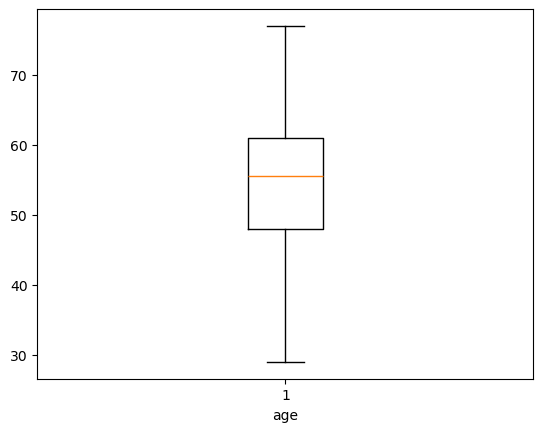

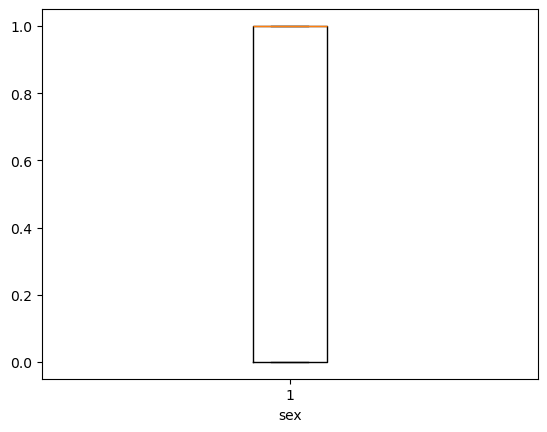

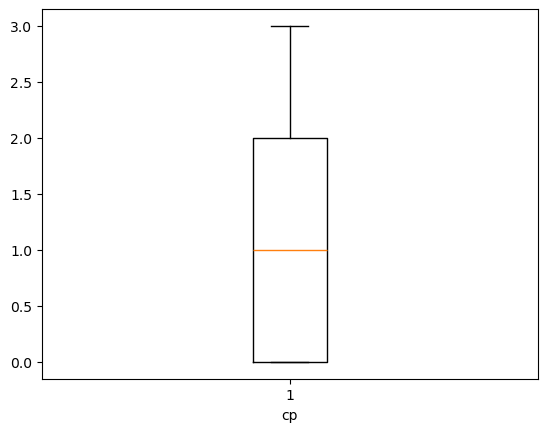

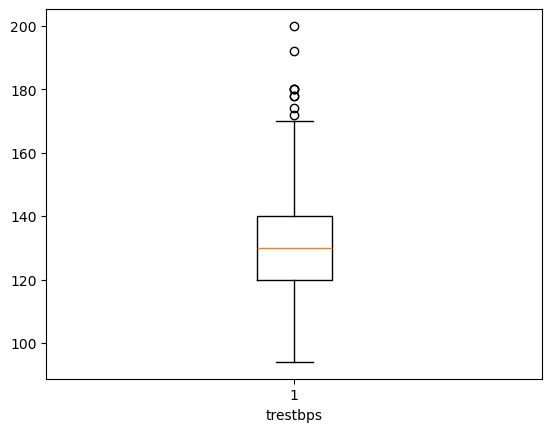

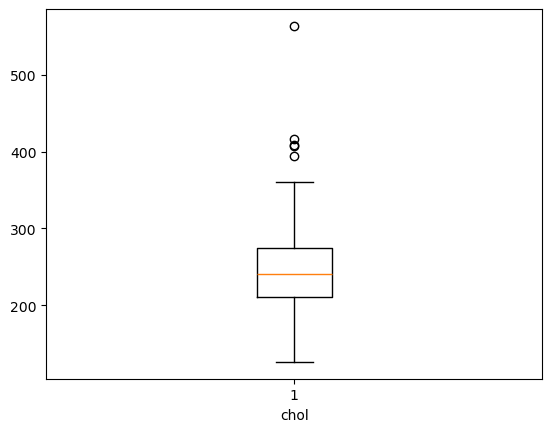

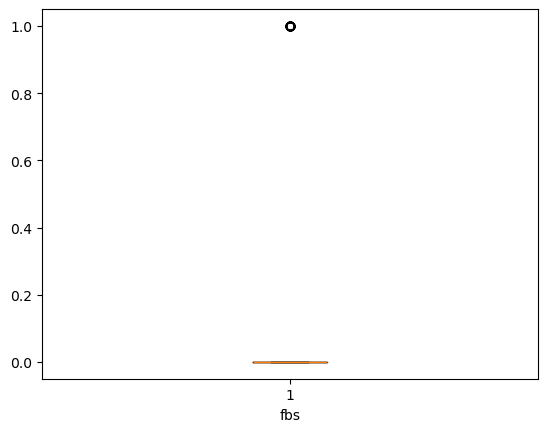

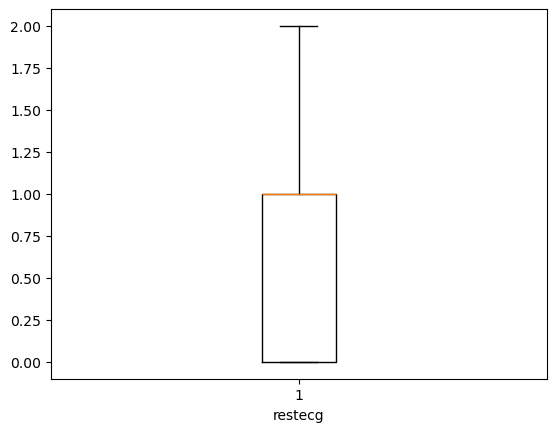

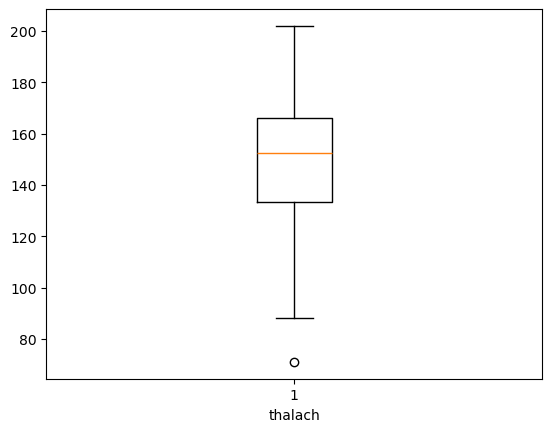

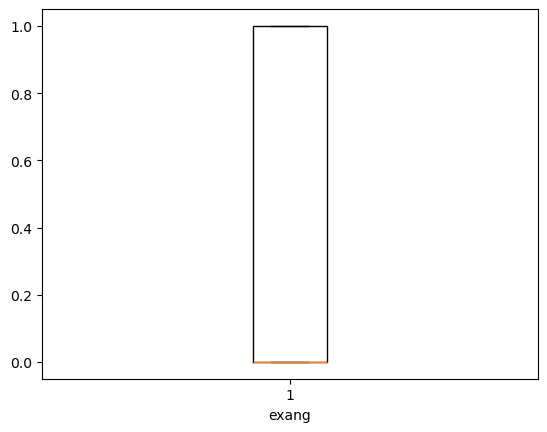

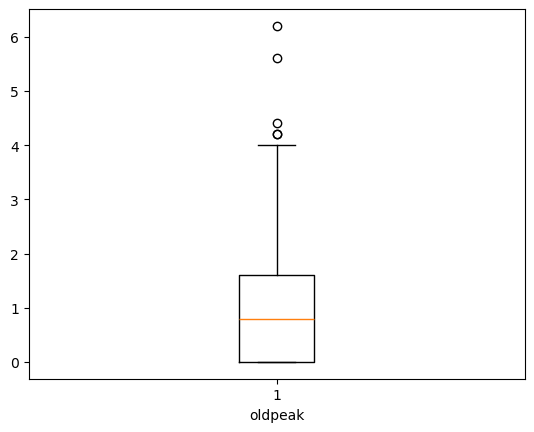

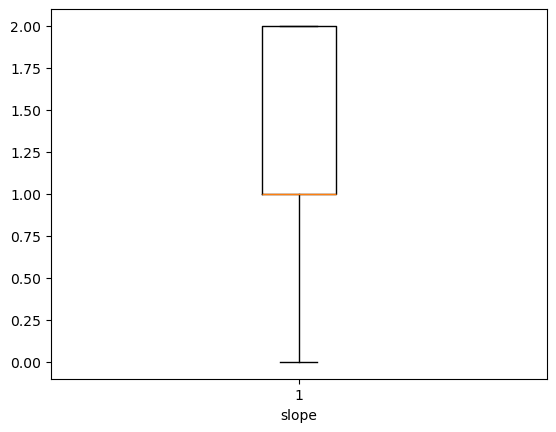

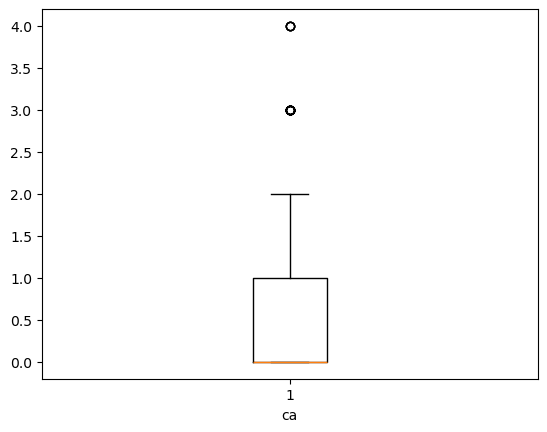

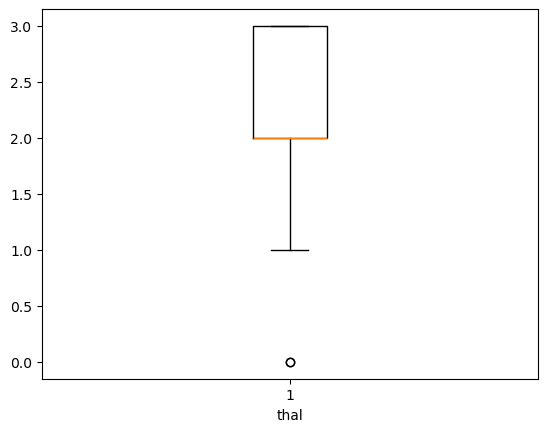

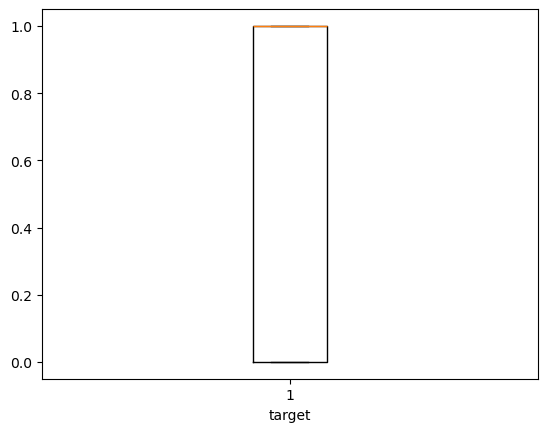

In [12]:
#Checck For the Outliers
for i in df.columns:
  if df[i].dtype!='object':
    plt.boxplot(df[i])
    plt.xlabel(i)
    plt.show()

As the dataset is a real patients information so we are not going to remove the outliers in that case.

And

As tree algorithm are robust to  outliers we can skip the outlier removal part.

**Model Building**

In [13]:
#Divide the data into independent and dependent variables
x=df.iloc[:,:-1]
y=df.iloc[:,-1]

In [14]:
x    #Independent Variables

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...
298,57,0,0,140,241,0,1,123,1,0.2,1,0,3
299,45,1,3,110,264,0,1,132,0,1.2,1,0,3
300,68,1,0,144,193,1,1,141,0,3.4,1,2,3
301,57,1,0,130,131,0,1,115,1,1.2,1,1,3


In [15]:
y   #Dependent Variable

0      1
1      1
2      1
3      1
4      1
      ..
298    0
299    0
300    0
301    0
302    0
Name: target, Length: 302, dtype: int64

In [16]:
from sklearn.model_selection import train_test_split

In [17]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=0)

In [18]:
x_train

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
74,43,0,2,122,213,0,1,165,0,0.2,1,0,2
153,66,0,2,146,278,0,0,152,0,0.0,1,1,2
64,58,1,2,140,211,1,0,165,0,0.0,2,0,2
296,63,0,0,124,197,0,1,136,1,0.0,1,0,2
288,57,1,0,110,335,0,1,143,1,3.0,1,1,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...
252,62,0,0,138,294,1,1,106,0,1.9,1,3,2
193,60,1,0,145,282,0,0,142,1,2.8,1,2,3
117,56,1,3,120,193,0,0,162,0,1.9,1,0,3
47,47,1,2,138,257,0,0,156,0,0.0,2,0,2


In [19]:
y_train

74     1
153    1
64     1
296    0
288    0
      ..
252    0
193    0
117    1
47     1
173    0
Name: target, Length: 241, dtype: int64

In [20]:
x_test

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
226,62,1,1,120,281,0,0,103,0,1.4,1,1,3
152,64,1,3,170,227,0,0,155,0,0.6,1,0,3
229,64,1,2,125,309,0,1,131,1,1.8,1,0,3
202,58,1,0,150,270,0,0,111,1,0.8,2,0,3
52,62,1,2,130,231,0,1,146,0,1.8,1,3,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...
146,44,0,2,118,242,0,1,149,0,0.3,1,1,2
302,57,0,1,130,236,0,0,174,0,0.0,1,1,2
26,59,1,2,150,212,1,1,157,0,1.6,2,0,2
108,50,0,1,120,244,0,1,162,0,1.1,2,0,2


In [23]:
y_test

226    0
152    1
229    0
202    0
52     1
      ..
146    1
302    0
26     1
108    1
89     1
Name: target, Length: 61, dtype: int64

In [22]:
from sklearn.tree import DecisionTreeClassifier

In [24]:
model=DecisionTreeClassifier()

In [25]:
model.criterion

'gini'

In [26]:
#Train the Model
model.fit(x_train,y_train)

DecisionTreeClassifier()

In [27]:
#Test the Model
y_pred=model.predict(x_test)

In [28]:
y_pred

array([0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 1, 1, 1, 0, 1, 0, 0, 1, 0,
       0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 1, 1, 0, 1, 1, 0, 0, 1, 0, 1, 0,
       0, 1, 1, 1, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1])

In [29]:
new_df=pd.DataFrame()
new_df['Actual Values']=y_test
new_df['Predicted Values']=y_pred
new_df

,Actual Values,Predicted Values
226,0,0
152,1,1
229,0,0
202,0,0
52,1,1
...,...,...
146,1,1
302,0,1
26,1,1
108,1,1


In [30]:
from sklearn.metrics import *

In [31]:
acc=accuracy_score(y_test,y_pred)

In [32]:
acc

0.7868852459016393

In [33]:
confusion_matrix(y_test,y_pred)

array([[22,  5],
       [ 8, 26]])

In [34]:
#[TN   FP
# FN   Tp]

In [35]:
24/27

0.8888888888888888

In [36]:
24/32

0.75

In [37]:
y_test.value_counts()

target
1    34
0    27
Name: count, dtype: int64

In [38]:
# support is number of data/rows we are taking

In [39]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.73      0.81      0.77        27
           1       0.84      0.76      0.80        34

    accuracy                           0.79        61
   macro avg       0.79      0.79      0.79        61
weighted avg       0.79      0.79      0.79        61



What is a Connfusion Matrix?

Confusion Matrix is a small table that shows how wrll your model performed.

It compares the actual values vs predicted values.

TP(True Positive): If the actual value is Positive and model also has predicted the positive value.

FN(False Negative): If the actual value is Positive and model Flasely Predicted the Negative Value.

FP(False Positive): If the actual value is Negative but my model has Falsely Predicted the Positive Value.

TN(True Negative): If the actual value is Negative and my model also has predicted the Negative Value.

Accuracy Score: How many correct predictions my model has got out of all the predictions.

Formula= TP+TN/TP+TN+FP+FN

Precision Score: How many of the Precited Positive cases were actually Positive?

Formula=TP/TP+FP

Recall Score: How many actual positive cases my model is able to catch?

Formula=TP/TP+FN

F1 Score: A balance between the precision and recall Formula = 2* [(Precision*Recall) / (Precision+Recall)]

In [40]:
precision_score(y_test,y_pred)

0.8387096774193549

In [41]:
precision_score(y_test,y_pred)

0.8387096774193549

Recall score is used to find whether the dataset is balanced or not. If you are not getting a good recall score it means that your dataset is not balanced.

In [42]:
train_acc = model.score(x_train, y_train)
test_acc = model.score(x_test, y_test)
print(train_acc)
print(test_acc)

1.0
0.7868852459016393


[Text(0.609375, 0.95, 'x[11] <= 0.5\ngini = 0.497\nsamples = 241\nvalue = [111, 130]'),
 Text(0.44494047619047616, 0.85, 'x[12] <= 2.5\ngini = 0.373\nsamples = 141\nvalue = [35, 106]'),
 Text(0.5271577380952381, 0.8999999999999999, 'True  '),
 Text(0.31845238095238093, 0.75, 'x[9] <= 2.7\ngini = 0.235\nsamples = 103\nvalue = [14, 89]'),
 Text(0.20833333333333334, 0.65, 'x[7] <= 83.5\ngini = 0.185\nsamples = 97\nvalue = [10, 87]'),
 Text(0.18452380952380953, 0.55, 'gini = 0.0\nsamples = 1\nvalue = [1, 0]'),
 Text(0.23214285714285715, 0.55, 'x[4] <= 272.0\ngini = 0.17\nsamples = 96\nvalue = [9, 87]'),
 Text(0.13095238095238096, 0.45, 'x[8] <= 0.5\ngini = 0.1\nsamples = 76\nvalue = [4, 72]'),
 Text(0.07142857142857142, 0.35, 'x[3] <= 109.0\ngini = 0.031\nsamples = 64\nvalue = [1, 63]'),
 Text(0.047619047619047616, 0.25, 'x[1] <= 0.5\ngini = 0.32\nsamples = 5\nvalue = [1, 4]'),
 Text(0.023809523809523808, 0.15, 'gini = 0.0\nsamples = 4\nvalue = [0, 4]'),
 Text(0.07142857142857142, 0.15, 'g

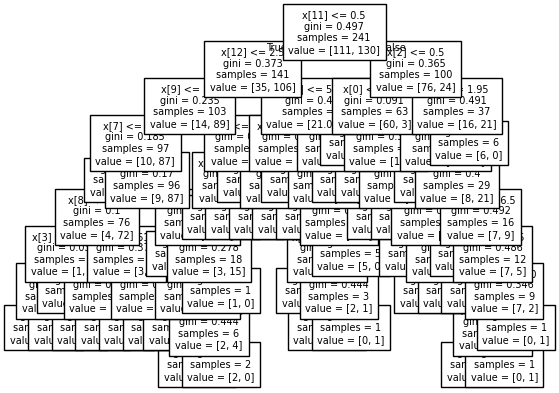

In [43]:
from sklearn import tree
tree.plot_tree(model,fontsize=7)

In [44]:
model.get_depth()

9

Overfitting: The model is Performing best on the training side but not performing good on the testing side.

Underfitting: The model is performing bad at the time of training as well as at the time of testing

In [46]:
model = DecisionTreeClassifier(max_depth=3)
model.fit(x_train, y_train)
y_pred = model.predict(x_test)
acc = accuracy_score(y_pred, y_test)
print("Max Depth: ", 3, "Accuracy is: ", acc)

Max Depth:  3 Accuracy is:  0.7704918032786885


In [47]:
# small (1-4) -> to capture simple pattens
# medium (5-10) -> ofter perform the best
# large (15+) -> may overfit

In [48]:
depth = [1,2,3,4,5,6,7,8,9,10,11,12,13,14]
for i in depth:
  model = DecisionTreeClassifier(max_depth=i, random_state=60)
  model.fit(x_train, y_train)
  y_pred = model.predict(x_test)
  acc = accuracy_score(y_test, y_pred)
  print("Max Depth:", i, "Accuracy is:", acc)

Max Depth: 1 Accuracy is: 0.6721311475409836
Max Depth: 2 Accuracy is: 0.819672131147541
Max Depth: 3 Accuracy is: 0.7704918032786885
Max Depth: 4 Accuracy is: 0.8360655737704918
Max Depth: 5 Accuracy is: 0.819672131147541
Max Depth: 6 Accuracy is: 0.7540983606557377
Max Depth: 7 Accuracy is: 0.7540983606557377
Max Depth: 8 Accuracy is: 0.7868852459016393
Max Depth: 9 Accuracy is: 0.7868852459016393
Max Depth: 10 Accuracy is: 0.7868852459016393
Max Depth: 11 Accuracy is: 0.7868852459016393
Max Depth: 12 Accuracy is: 0.7868852459016393
Max Depth: 13 Accuracy is: 0.7868852459016393
Max Depth: 14 Accuracy is: 0.7868852459016393


In [49]:
x

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...
298,57,0,0,140,241,0,1,123,1,0.2,1,0,3
299,45,1,3,110,264,0,1,132,0,1.2,1,0,3
300,68,1,0,144,193,1,1,141,0,3.4,1,2,3
301,57,1,0,130,131,0,1,115,1,1.2,1,1,3


In [50]:
y

0      1
1      1
2      1
3      1
4      1
      ..
298    0
299    0
300    0
301    0
302    0
Name: target, Length: 302, dtype: int64

In [51]:
x_test

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
226,62,1,1,120,281,0,0,103,0,1.4,1,1,3
152,64,1,3,170,227,0,0,155,0,0.6,1,0,3
229,64,1,2,125,309,0,1,131,1,1.8,1,0,3
202,58,1,0,150,270,0,0,111,1,0.8,2,0,3
52,62,1,2,130,231,0,1,146,0,1.8,1,3,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...
146,44,0,2,118,242,0,1,149,0,0.3,1,1,2
302,57,0,1,130,236,0,0,174,0,0.0,1,1,2
26,59,1,2,150,212,1,1,157,0,1.6,2,0,2
108,50,0,1,120,244,0,1,162,0,1.1,2,0,2


**Hyperparameter Tuning ->**
It is a process of finding the best combition parameters for your model

Criterion ->
 1.Gini (defauly) -> faster
 2.entropy (information gain) -> prefer more information measure
max_depth -> Limits how deep the tree can go
min_samples_split -> minimum number of samples required to split a node
1. default -> 2
Higher value -> Tree grows slower -> prevent overfitting

min_samples_leaf -> Minimum number of samples required to be at a leaf node

In [52]:
        # GridSearchCV ->

# It will take a list of parameters
# tries every combitation
# use cross validation (cv=5 -> divide your data into 5 parts)
# pick the best parameters from all the list

In [53]:
from sklearn.model_selection import GridSearchCV

In [54]:
grid_params = {
    "criterion" : ["gini", "entropy"],
    "max_depth" : [1,5,50,100],
    "random_state" : [0,1,2,3,4,5],
    "min_samples_split" : [2,6,8,9,3,5,22],
    "min_samples_leaf" : [1,4,6,7,9]
}

In [55]:
new_model = DecisionTreeClassifier()

In [58]:
# Cv -> Cross validation, it means your data will be splitted into 3 parts and 
#model will train 2 time and test 1->evaluate ->3 time

In [59]:
gSearch = GridSearchCV(estimator=new_model, param_grid=grid_params, cv=3)

In [60]:
gSearch.fit(x_train, y_train)

GridSearchCV(cv=3, estimator=DecisionTreeClassifier(),
             param_grid={'criterion': ['gini', 'entropy'],
                         'max_depth': [1, 5, 50, 100],
                         'min_samples_leaf': [1, 4, 6, 7, 9],
                         'min_samples_split': [2, 6, 8, 9, 3, 5, 22],
                         'random_state': [0, 1, 2, 3, 4, 5]})

In [61]:
gSearch.best_params_

{'criterion': 'gini',
 'max_depth': 5,
 'min_samples_leaf': 9,
 'min_samples_split': 2,
 'random_state': 0}

In [62]:
gSearch.best_estimator_

DecisionTreeClassifier(max_depth=5, min_samples_leaf=9, random_state=0)

In [63]:
new_model_dt = gSearch.best_estimator_

In [64]:
predict = new_model_dt.predict(x_test)

In [65]:
accuracy_score(predict, y_test)

0.8360655737704918